In [12]:
import pandas as pd
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [6]:
# Initializing the graph from data

nodes = pd.read_csv(
    "../data/hep-th-slacdates.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["id", "date"], 
    dtype=str  
)


edges = pd.read_csv(
    "../data/hep-th-citations.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["From", "To"], 
    dtype=str
)

# 3. Get unique node IDs from both columns of the edge list
node_ids = pd.unique(edges[["From", "To"]].values.ravel())

# 4. Get actual nodes listed in edge list
nodes_used = nodes[nodes["id"].isin(node_ids)].copy()

# 5. Make a directed graph smoothly
g_directed = nx.DiGraph()

# Convert the filtered nodes dataframe into a dictionary of attributes and load them
node_attributes = nodes_used.set_index("id").to_dict("index")
g_directed.add_nodes_from(node_attributes.keys())
nx.set_node_attributes(g_directed, node_attributes)

# Add the edges directly from the edge dataframe tuples
g_directed.add_edges_from(edges.itertuples(index=False, name=None))

# Print properties to verify success
print("--- GRAPH INITIALIZATION SUCCESSFUL ---")
print(f"Nodes in graph: {g_directed.number_of_nodes()}")
print(f"Edges in graph: {g_directed.number_of_edges()}")

--- GRAPH INITIALIZATION SUCCESSFUL ---
Nodes in graph: 27770
Edges in graph: 352807


In [7]:
# Null values check
print(f"Nulls in From column: {edges['From'].isna().sum()}")
print(f"Nulls in To column:   {edges['To'].isna().sum()}")

Nulls in From column: 0
Nulls in To column:   0


In [8]:
# Identify cross-listed papers (starting with "11")
crosslisted_dates = nodes[nodes["id"].str.startswith("11", na=False)].shape[0]
crosslisted_citations = edges[edges["From"].str.startswith("11", na=False) | edges["To"].str.startswith("11", na=False)].shape[0]
print(f"Crosslisted rows in dates file: {crosslisted_dates}")
print(f"Crosslisted rows in citations file: {crosslisted_citations}")

Crosslisted rows in dates file: 0
Crosslisted rows in citations file: 0


In [9]:
# Get all unique nodes active in edge pairs
edges_nodes = pd.unique(edges[["From", "To"]].values.ravel())
vertices_nodes = nodes["id"].unique()

In [11]:
# Find structural mismatch anomalies
problem_nodes = np.setdiff1d(edges_nodes, vertices_nodes)
print(f"\n--- TARGETED GRAPH MATCHING DIAGNOSTIC ---")
print(f"Total unique nodes found in edge links: {len(edges_nodes)}")
print(f"Total unique nodes found in dates file: {len(vertices_nodes)}")
print(f"Number of offending nodes missing metadata: {len(problem_nodes)}")


--- TARGETED GRAPH MATCHING DIAGNOSTIC ---
Total unique nodes found in edge links: 27770
Total unique nodes found in dates file: 29555
Number of offending nodes missing metadata: 0


# Summary of the network properties

In [ ]:
in_deg = dict(g_directed.in_degree())
out_deg = dict(g_directed.out_degree())
in_vals, out_vals = list(in_deg.values()), list(out_deg.values())
is_strongly_connected = nx.is_strongly_connected(g_directed)
is_weakly_connected = nx.is_weakly_connected(g_directed)

scc = list(nx.strongly_connected_components(g_directed))
wcc = list(nx.weakly_connected_components(g_directed))
clustering = list(nx.clustering(g_directed).values())
# avg_path_length = nx.average_shortest_path_length(g_directed)

summary_data = {
    "Network Property": [
        "Total Vertices (Papers)", "Total Edges (Citations)", "Network Density",
        "Strongly Connected ?", "Weakly Connected ?",
        "Mean In-Degree (Citations Received)", "Max In-Degree (Top Paper)",
        "Mean Out-Degree (References Given)", "Max Out-Degree (Longest Bibliography)",
        "Total Weakly Connected Components", "Size of Largest Connected Component (WCC)",
        "Total Strongly Connected Components (Cycles)", "Size of Largest Cyclic Component (SCC)",
        "Mean Local Clustering Coefficient"
    ],
    "Value": [
        g_directed.number_of_nodes(), g_directed.number_of_edges(), f"{nx.density(g_directed):.6f}",
        is_strongly_connected, is_weakly_connected,  
        f"{np.mean(in_vals):.2f}", np.max(in_vals),
        f"{np.mean(out_vals):.2f}", np.max(out_vals),
        len(wcc), max(len(c) for c in wcc),
        len(scc), max(len(c) for c in scc),
        f"{np.mean(clustering):.4f}",
        # f"{avg_path_length:.4f}"
    ]
}

network_summary = pd.DataFrame(summary_data)
print("\n=== THE TOPOLOGICAL PROFILE OF THE NETWORK ===")
print(network_summary.to_string(index=False))


=== THE TOPOLOGICAL PROFILE OF THE NETWORK ===
                            Network Property    Value
                     Total Vertices (Papers)    27770
                     Total Edges (Citations)   352807
                             Network Density 0.000458
                        Strongly Connected ?    False
                          Weakly Connected ?    False
         Mean In-Degree (Citations Received)    12.70
                   Max In-Degree (Top Paper)     2414
          Mean Out-Degree (References Given)    12.70
       Max Out-Degree (Longest Bibliography)      562
           Total Weakly Connected Components      143
   Size of Largest Connected Component (WCC)    27400
Total Strongly Connected Components (Cycles)    20086
      Size of Largest Cyclic Component (SCC)     7464
           Mean Local Clustering Coefficient   0.1569


In [15]:
largest_wcc_nodes = max(nx.weakly_connected_components(g_directed), key=len)
g_largest_wcc = g_directed.subgraph(largest_wcc_nodes)

g_undirected_wcc = g_largest_wcc.to_undirected()

avg_path_length = nx.average_shortest_path_length(g_undirected_wcc)

print(f"Average Path Length of the wCC {avg_path_length}")

Average Path Length of the wCC 4.278680083960654


# In-Degree Plot

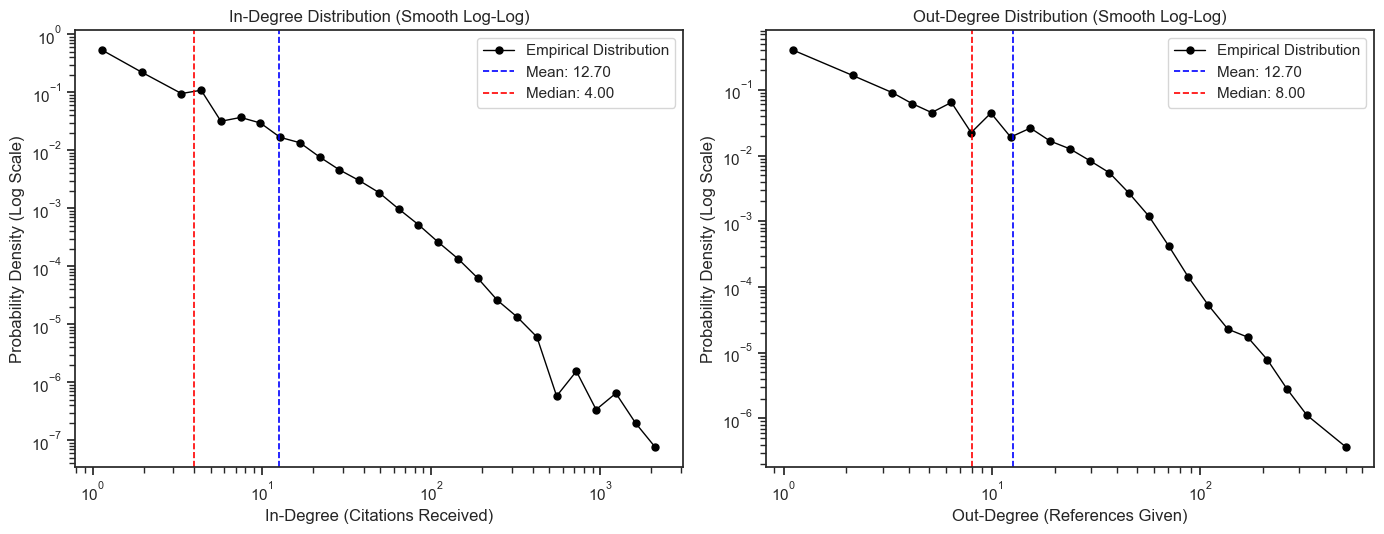

In [24]:
sns.set_theme(style="ticks")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- HELPER FUNCTION FOR CLEAN LOG-LINED DISTRIBUTIONS ---
def plot_clean_log_distribution(values, ax, title, xlabel):
    vals_series = pd.Series(values)
    vals_filtered = vals_series[vals_series > 0]
    
    # 1. Generate 30 clean log-spaced bins
    bins = np.logspace(np.log10(vals_filtered.min()), np.log10(vals_filtered.max()), 30)
    
    # 2. Use pandas.cut to digitize the data points into these bins
    bin_assignments = pd.cut(vals_filtered, bins=bins, include_lowest=True)
    
    # 3. Calculate the normalized density for each bin
    counts = bin_assignments.value_counts(sort=False)
    bin_widths = np.diff(bins)
    densities = counts.values / (len(vals_filtered) * bin_widths)
    
    # 4. Find the exact geometric center point of each bin for the scatter markers
    bin_centers = np.sqrt(bins[:-1] * bins[1:])
    
    # 5. Filter out empty bins to avoid drawing broken lines to log(0)
    valid = densities > 0
    
    # 6. Plot a clean continuous line with clear dot markers
    ax.plot(bin_centers[valid], densities[valid], 'o-', color='black', 
            markersize=5, linewidth=1, label='Empirical Distribution')
    
    # Structural overlays
    ax.axvline(np.mean(values), color='blue', linestyle='--', linewidth=1.2, 
               label=f"Mean: {np.mean(values):.2f}")
    ax.axvline(np.median(values), color='red', linestyle='--', linewidth=1.2, 
               label=f"Median: {np.median(values):.2f}")
    
    # Axis formatting
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability Density (Log Scale)")
    ax.legend()

# --- EXECUTE ON YOUR METRICS ---
plot_clean_log_distribution(in_vals, axes[0], "In-Degree Distribution (Smooth Log-Log)", "In-Degree (Citations Received)")
plot_clean_log_distribution(out_vals, axes[1], "Out-Degree Distribution (Smooth Log-Log)", "Out-Degree (References Given)")

plt.tight_layout()
plt.show()



In [ ]:
nodes_used["year"] = pd.to_numeric(nodes_used["date"].str.slice(0,4), errors='coerce')
nx.set_node_attributes(g_directed, nodes_used.set_index("id")["year"].to_dict(), "year")

In [ ]:
os.makedirs('oslom_inputs', exist_ok = True)

for current_year in range(1992, 2004):
    active_ids = nodes_used[nodes_used['year'] <= current_year]["id"]
    year_edges = edges[edges["From"].isin(active_ids) & edges["To"].isin(active_ids)]

    filePath = f"oslom_inputs/network_{current_year}.txt"
    year_edges.to_csv(filePath, sep = " ", header = False, index = False)

    print(f"Exported clean snapshot for Year {current_year} -> {filePath}")


Exported clean snapshot for Year 1992 -> oslom_inputs/network_1992.txt
Exported clean snapshot for Year 1993 -> oslom_inputs/network_1993.txt
Exported clean snapshot for Year 1994 -> oslom_inputs/network_1994.txt
Exported clean snapshot for Year 1995 -> oslom_inputs/network_1995.txt
Exported clean snapshot for Year 1996 -> oslom_inputs/network_1996.txt
Exported clean snapshot for Year 1997 -> oslom_inputs/network_1997.txt
Exported clean snapshot for Year 1998 -> oslom_inputs/network_1998.txt
Exported clean snapshot for Year 1999 -> oslom_inputs/network_1999.txt
Exported clean snapshot for Year 2000 -> oslom_inputs/network_2000.txt
Exported clean snapshot for Year 2001 -> oslom_inputs/network_2001.txt
Exported clean snapshot for Year 2002 -> oslom_inputs/network_2002.txt
Exported clean snapshot for Year 2003 -> oslom_inputs/network_2003.txt


In [13]:
for current_year in range(1995, 2004):
    
    # Every window is now guaranteed to be exactly 4 years long
    start_year = current_year - 3
    
    # Filter IDs that fall strictly within this uniform 4-year bracket
    active_ids = nodes_used[(nodes_used['year'] >= start_year) & (nodes_used['year'] <= current_year)]["id"]
    
    # Isolate edges where BOTH the citing paper and cited paper belong to this active window
    year_edges = edges[edges["From"].isin(active_ids) & edges["To"].isin(active_ids)]
    
    # Construct the descriptive, symmetric file name
    filePath = f"oslom_inputs/network_{start_year}_{current_year}.txt"
    
    # Export to a clean, space-separated format for OSLOM
    year_edges.to_csv(filePath, sep=" ", header=False, index=False)
    
    print(f"Exported uniform sliding window snapshot ({start_year} to {current_year}) -> {filePath}")

Exported uniform sliding window snapshot (1992 to 1995) -> oslom_inputs/network_1992_1995.txt
Exported uniform sliding window snapshot (1993 to 1996) -> oslom_inputs/network_1993_1996.txt
Exported uniform sliding window snapshot (1994 to 1997) -> oslom_inputs/network_1994_1997.txt
Exported uniform sliding window snapshot (1995 to 1998) -> oslom_inputs/network_1995_1998.txt
Exported uniform sliding window snapshot (1996 to 1999) -> oslom_inputs/network_1996_1999.txt
Exported uniform sliding window snapshot (1997 to 2000) -> oslom_inputs/network_1997_2000.txt
Exported uniform sliding window snapshot (1998 to 2001) -> oslom_inputs/network_1998_2001.txt
Exported uniform sliding window snapshot (1999 to 2002) -> oslom_inputs/network_1999_2002.txt
Exported uniform sliding window snapshot (2000 to 2003) -> oslom_inputs/network_2000_2003.txt
